In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path(r"d:\ML Project - E-commerce product search with semantic ranking")
DATA = ROOT / "data"
DOCS = ROOT / "docs"
sys.path.append(str(ROOT))

from src.evaluate import evaluate_run

qrels = pd.read_parquet(DATA / "qrels.parquet")

runs = {
    "BM25": "run_bm25.parquet",
    "Semantic": "run_semantic.parquet",
    "Hybrid": "run_hybrid.parquet",
    "Hybrid + Re-ranker": "run_rerank.parquet",
}

rows = []
for name, fname in runs.items():
    run = pd.read_parquet(DATA / fname)
    s = evaluate_run(run, qrels, k=10)
    rows.append({"Method": name, **s})

results = pd.DataFrame(rows)
results.to_csv(DATA / "results.csv", index=False)
results

,Method,Recall@10,MRR@10,NDCG@10,queries_evaluated
0,BM25,0.3362,0.7332,0.4952,500
1,Semantic,0.3360,0.7456,0.4986,500
2,Hybrid,0.3673,0.7583,0.5335,500
3,Hybrid + Re-ranker,0.4045,0.8103,0.5953,500


In [2]:
base = results.loc[results["Method"] == "BM25", "NDCG@10"].iloc[0]
results["NDCG vs BM25 (%)"] = ((results["NDCG@10"] - base) / base * 100).round(1)
results[["Method", "Recall@10", "MRR@10", "NDCG@10", "NDCG vs BM25 (%)"]]

,Method,Recall@10,MRR@10,NDCG@10,NDCG vs BM25 (%)
0,BM25,0.3362,0.7332,0.4952,0.0
1,Semantic,0.3360,0.7456,0.4986,0.7
2,Hybrid,0.3673,0.7583,0.5335,7.7
3,Hybrid + Re-ranker,0.4045,0.8103,0.5953,20.2


In [3]:
cols = ["Method", "Recall@10", "MRR@10", "NDCG@10", "NDCG vs BM25 (%)"]
tbl = results[cols]

lines = ["| " + " | ".join(cols) + " |",
         "|" + "|".join(["---"] * len(cols)) + "|"]
for _, r in tbl.iterrows():
    lines.append("| " + " | ".join(str(v) for v in r.values) + " |")

print("\n".join(lines))

| Method | Recall@10 | MRR@10 | NDCG@10 | NDCG vs BM25 (%) |
|---|---|---|---|---|
| BM25 | 0.3362 | 0.7332 | 0.4952 | 0.0 |
| Semantic | 0.336 | 0.7456 | 0.4986 | 0.7 |
| Hybrid | 0.3673 | 0.7583 | 0.5335 | 7.7 |
| Hybrid + Re-ranker | 0.4045 | 0.8103 | 0.5953 | 20.2 |


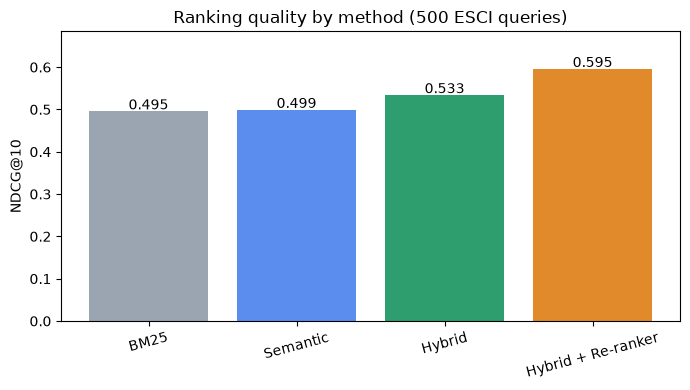

In [4]:
DOCS.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(results["Method"], results["NDCG@10"],
              color=["#9aa5b1", "#5b8def", "#2f9e6f", "#e08a2c"])

for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005,
            f"{b.get_height():.3f}", ha="center", fontsize=10)

ax.set_ylabel("NDCG@10")
ax.set_title("Ranking quality by method (500 ESCI queries)")
ax.set_ylim(0, max(results["NDCG@10"]) * 1.15)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(DOCS / "results_ndcg.png", dpi=150)
plt.show()

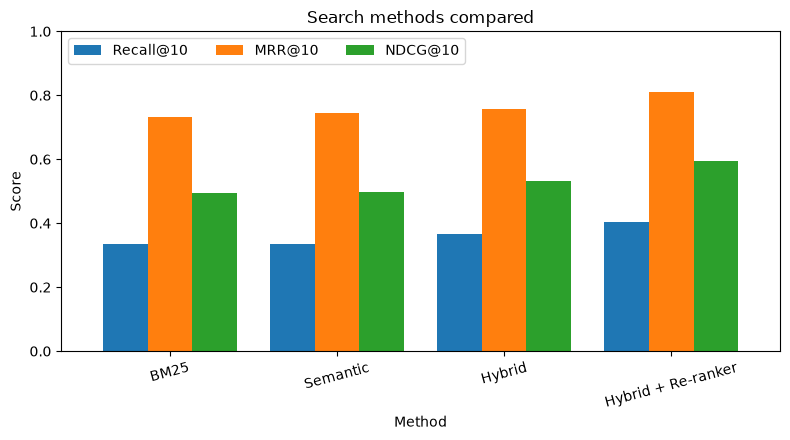

In [5]:
metrics = ["Recall@10", "MRR@10", "NDCG@10"]
ax = results.set_index("Method")[metrics].plot(kind="bar", figsize=(8, 4.5), width=0.8)

ax.set_ylabel("Score")
ax.set_title("Search methods compared")
ax.set_ylim(0, 1)
ax.legend(loc="upper left", ncol=3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(DOCS / "results_all_metrics.png", dpi=150)
plt.show()

In [6]:
latency = pd.DataFrame({
    "Method": ["BM25", "Semantic", "Hybrid", "Hybrid + Re-ranker"],
    "Latency (ms)": [0, 0, 0, 0],   # <-- replace with YOUR measured numbers
})
latency

,Method,Latency (ms)
0,BM25,0
1,Semantic,0
2,Hybrid,0
3,Hybrid + Re-ranker,0
